###<font color='red'>Made by Anton Rudchenko for ParKinSim (Parallel Kinematic Simulation) project.</font>


This book is about revisiting and validation of ML models cheecked before for solving reverse kinematics of a Pentapod, with enriched dataset divided during normalization attempt into 2 datasets, 1st the biggest one for training of the model, 2nd one - for fair validation, considering that the model has not been trained with configurations from it (unseen data).

In [ ]:
#@title <font color='yellow'>Imports

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

##<font color='yellow'>Importing and preprocessing data collected from solving direct kinematics in simulation.

In [ ]:
data = pd.read_csv('filtered_first.csv').drop_duplicates()

print(data)

         L1    L2    L3    L4    L5       X       Y       Z     RX     RY     RZ
0      14.0  16.0  15.0  15.0  15.0   6.225 -36.857 -29.095  0.255  0.039  0.045
1      13.0  16.0  15.0  15.0  15.0   6.911 -39.529 -26.396  0.274  0.043  0.048
2      12.0  16.0  15.0  15.0  15.0   7.764 -43.206 -23.034  0.301  0.047  0.052
3      11.0  16.0  15.0  15.0  15.0   8.963 -48.874 -18.280  0.342  0.054  0.058
4      11.0  15.0  15.0  15.0  15.0   7.614 -56.939 -13.149  0.400  0.042  0.046
...     ...   ...   ...   ...   ...     ...     ...     ...    ...    ...    ...
17572   3.0   4.0  39.0  23.0  39.0 -27.902  82.199 -40.218 -0.450 -0.207 -0.089
17573   3.0   4.0  39.0  27.0  39.0 -32.052  87.061 -36.371 -0.506 -0.244 -0.094
17574   3.0   4.0  39.0  31.0  39.0 -35.923  91.424 -32.105 -0.561 -0.279 -0.094
17575   3.0   4.0  39.0  33.0  39.0 -37.765  93.431 -29.821 -0.589 -0.296 -0.093
17576   3.0   4.0  39.0  35.0  39.0 -39.549  95.328 -27.440 -0.616 -0.314 -0.091

[17577 rows x 11 columns]


In [ ]:
labels = data[['L1', 'L2', 'L3', 'L4', 'L5']]
features = data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

In [ ]:
#@title plotting function
# ChatGPT made it for me ;3

def plot_comparison(actual, predicted, labels=['X', 'Y', 'Z', 'Rx', 'Ry', 'Rz']):
    """
    Plot a comparison of actual vs. predicted values for each parameter, excluding invalid data.
    Prints accuracy for each parameter.

    Parameters:
    - actual: List of actual values for each parameter (list of lists).
    - predicted: List of predicted values for each parameter (list of lists).
    - labels: Labels for each parameter.
    """
    # Check if the lists have the same length
    if len(actual) != len(predicted):
        raise ValueError("Actual and predicted lists must have the same length")

    # Extract individual parameters (e.g., X, Y, Z, Rx, Ry, Rz)
    actual = list(zip(*actual))  # Transpose to separate parameters
    predicted = list(zip(*predicted))

    # Check if labels match the number of parameters
    if len(labels) != len(actual):
        raise ValueError("Number of labels must match the number of parameters in actual/predicted data.")

    # Determine grid size for subplots
    num_plots = len(labels)
    cols = 3  # Fixed number of columns (can be adjusted)
    rows = (num_plots + cols - 1) // cols  # Calculate required rows

    # Create subplots dynamically
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 4))
    axes = axes.flatten()  # Flatten axes for easy indexing

    for i, ax in enumerate(axes):
        if i < num_plots:  # Plot only if there's data
            # Filter valid data for plotting and accuracy
            valid_pairs = [
                (a, p) for a, p in zip(actual[i], predicted[i]) if a != 999.0 and p != 999.0
            ]
            valid_actual = [pair[0] for pair in valid_pairs]
            valid_predicted = [pair[1] for pair in valid_pairs]

            # Calculate accuracy (MAPE)
            if len(valid_actual) > 0:  # Avoid division by zero
                valid_actual_np = np.array(valid_actual)
                valid_predicted_np = np.array(valid_predicted)
                mape = np.mean(np.abs((valid_actual_np - valid_predicted_np) / valid_actual_np)) * 100
                accuracy = 100 - mape  # Accuracy as complement of error
                print(f'Accuracy for {labels[i]}: {accuracy:.2f}%')
            else:
                print(f'Accuracy for {labels[i]}: No valid data')

            # Plot valid actual and predicted values
            ax.plot(range(len(valid_actual)), valid_actual, label='Actual', marker='o', linestyle='-', alpha=0.7)
            ax.plot(range(len(valid_predicted)), valid_predicted, label='Predicted', marker='x', linestyle='--', alpha=0.7)

            # Add labels, title, and legend
            ax.set_title(f'Comparison for {labels[i]}')
            ax.set_xlabel('Index')
            ax.set_ylabel(labels[i])
            ax.legend()
            ax.grid(True)
        else:
            # Hide unused subplots
            ax.axis('off')

##<font color='orange'>Random Forest Regressor model evaluation

Performance Metrics:
Target L1:
  Mean Squared Error: 8.5616
  R2 Score: 0.9899
Target L2:
  Mean Squared Error: 12.2874
  R2 Score: 0.9790
Target L3:
  Mean Squared Error: 7.2566
  R2 Score: 0.9903
Target L4:
  Mean Squared Error: 11.8611
  R2 Score: 0.9806
Target L5:
  Mean Squared Error: 7.1914
  R2 Score: 0.9901

Feature Importances:
    Importance
X     0.164354
Y     0.203993
Z     0.289164
RX    0.119889
RY    0.037147
RZ    0.185455


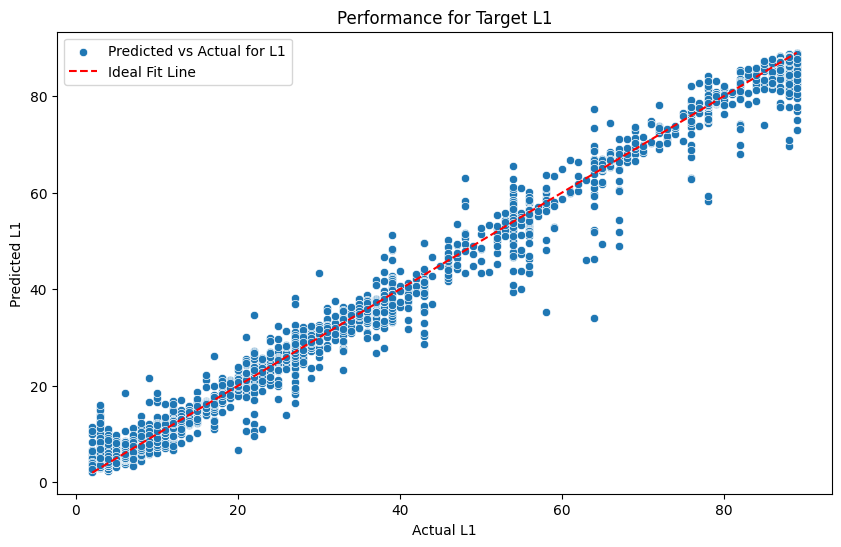

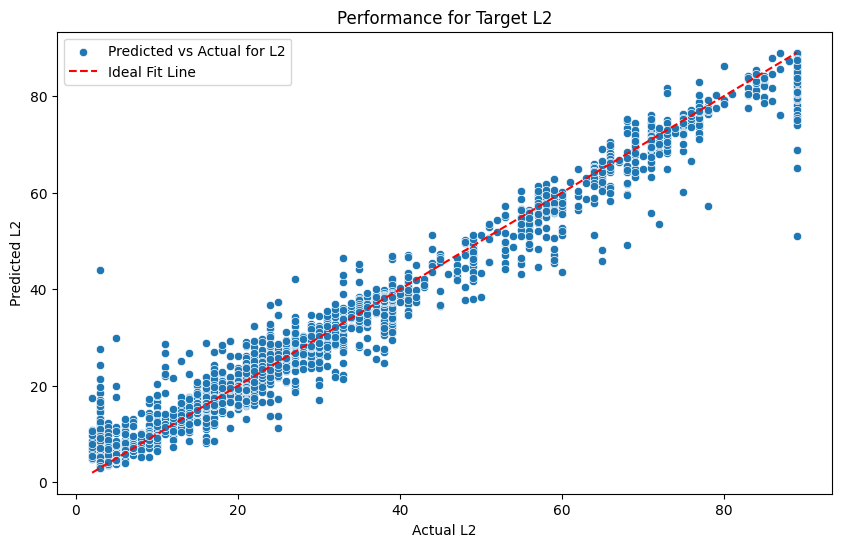

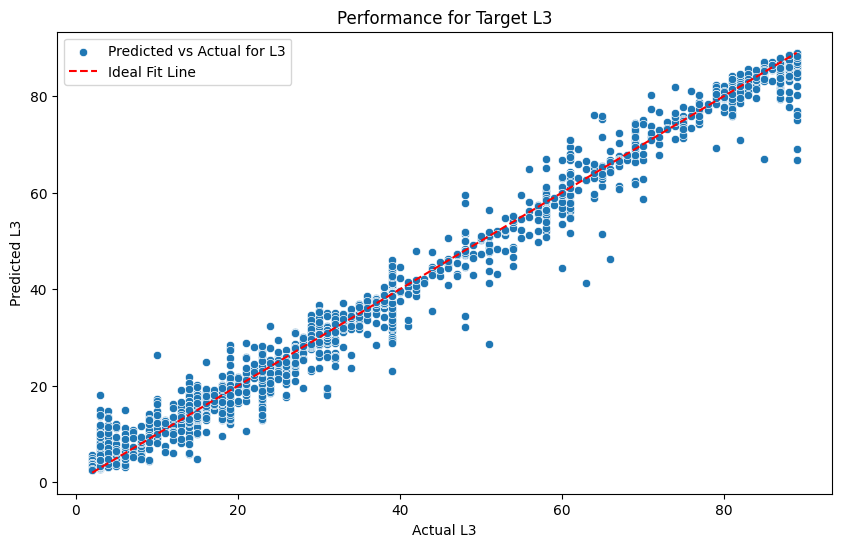

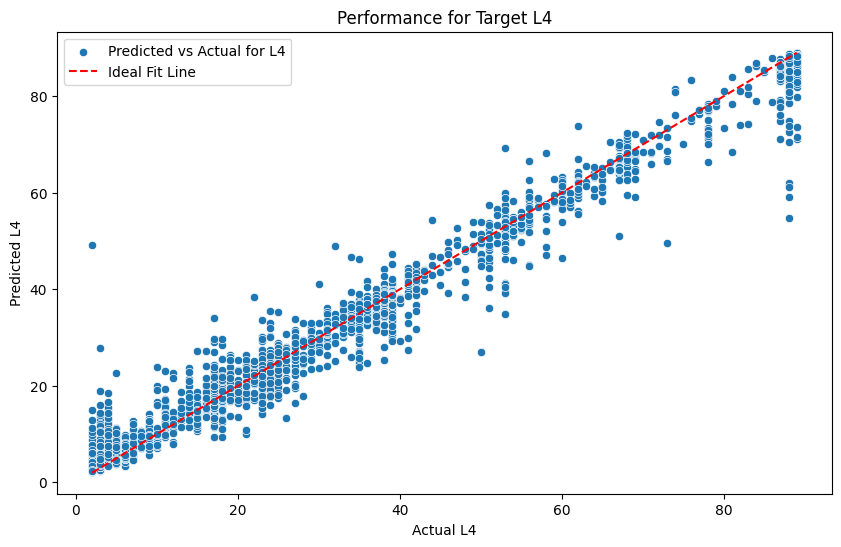

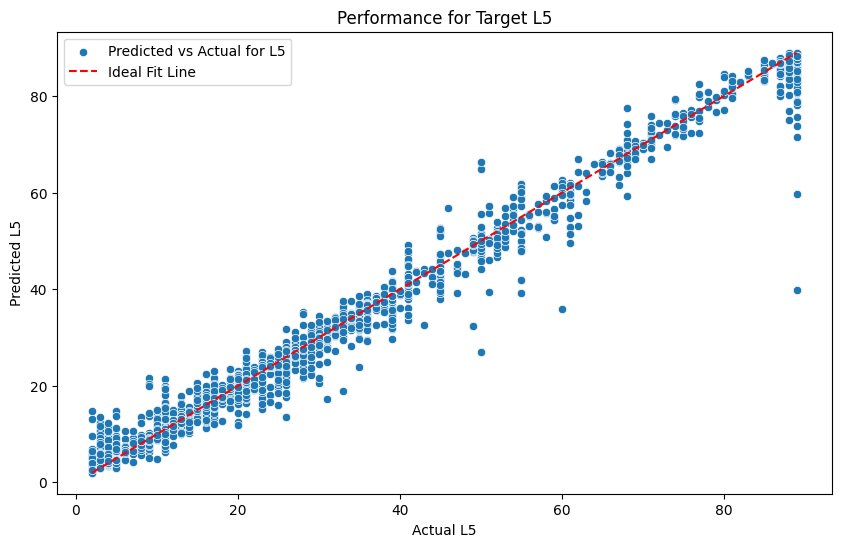

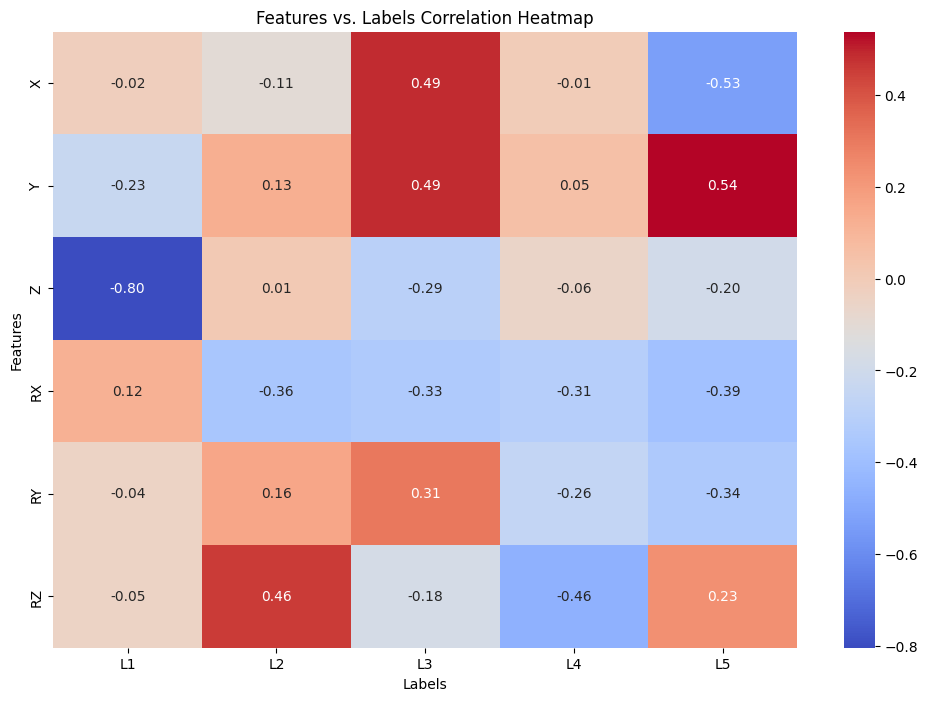

In [ ]:
#@title Defining and training the model
from sklearn.ensemble import RandomForestRegressor



labels = data[['L1', 'L2', 'L3', 'L4', 'L5']]
features = data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred, multioutput='raw_values')
r2 = r2_score(y_test, y_pred, multioutput='raw_values')

print("Performance Metrics:")
for i, target in enumerate(labels):
    print(f"Target {target}:")
    print(f"  Mean Squared Error: {mse[i]:.4f}")
    print(f"  R2 Score: {r2[i]:.4f}")

feature_importances = pd.DataFrame(model.feature_importances_, index=features.columns, columns=['Importance'])

print("\nFeature Importances:")
print(feature_importances)

# Feature importances
feature_importances = pd.DataFrame({
    'Feature': features.columns,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)


# Visualization
for i, target in enumerate(labels):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_test.iloc[:, i], y=y_pred[:, i], label=f'Predicted vs Actual for {target}')
    plt.plot([y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
            [y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
            color='red', linestyle='--', label='Ideal Fit Line')
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Performance for Target {target}")
    plt.legend()
    plt.show()

#Heatmap: Features vs. Labels
correlation_matrix = pd.concat([features, labels], axis=1).corr()
correlation_features_labels = correlation_matrix.loc[features.columns, labels.columns]

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_features_labels, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Features vs. Labels Correlation Heatmap")
plt.xlabel("Labels")
plt.ylabel("Features")
plt.show()


In [ ]:
#@title Validating using unseen data
new_data = pd.read_csv('filtered_second.csv').drop_duplicates()
#print(data)


X = new_data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']].values[:100]
y = new_data[['L1', 'L2', 'L3', 'L4', 'L5']].values[:100]

def make_prediction(desired):
    feature_names = ['X', 'Y', 'Z', 'RX', 'RY', 'RZ'] # there were too many warning because of passing np array without features names
    xyzrxryrz = pd.DataFrame([desired], columns=feature_names)

    prediction = model.predict(xyzrxryrz)

    res = prediction[0].tolist()

    return res

res = []
for i in X:
    y_pred = make_prediction(i)
    res.append(y_pred)

res = np.array(res)

#print(res)

# writing predicted configurations into a text file for further validation in simulation
with open('predictions_rfr.txt', 'w') as writefile:
    for i in res:
        #print(i)
        writefile.write(f'{i[0]}, {i[1]}, {i[2]}, {i[3]}, {i[4]}\n')

There are 1 failed simulations, which is 1.0%

Accuracy for X: 93.70%
Accuracy for Y: 97.18%
Accuracy for Z: 81.91%
Accuracy for RX: 95.84%
Accuracy for RY: 95.72%
Accuracy for RZ: 81.76%


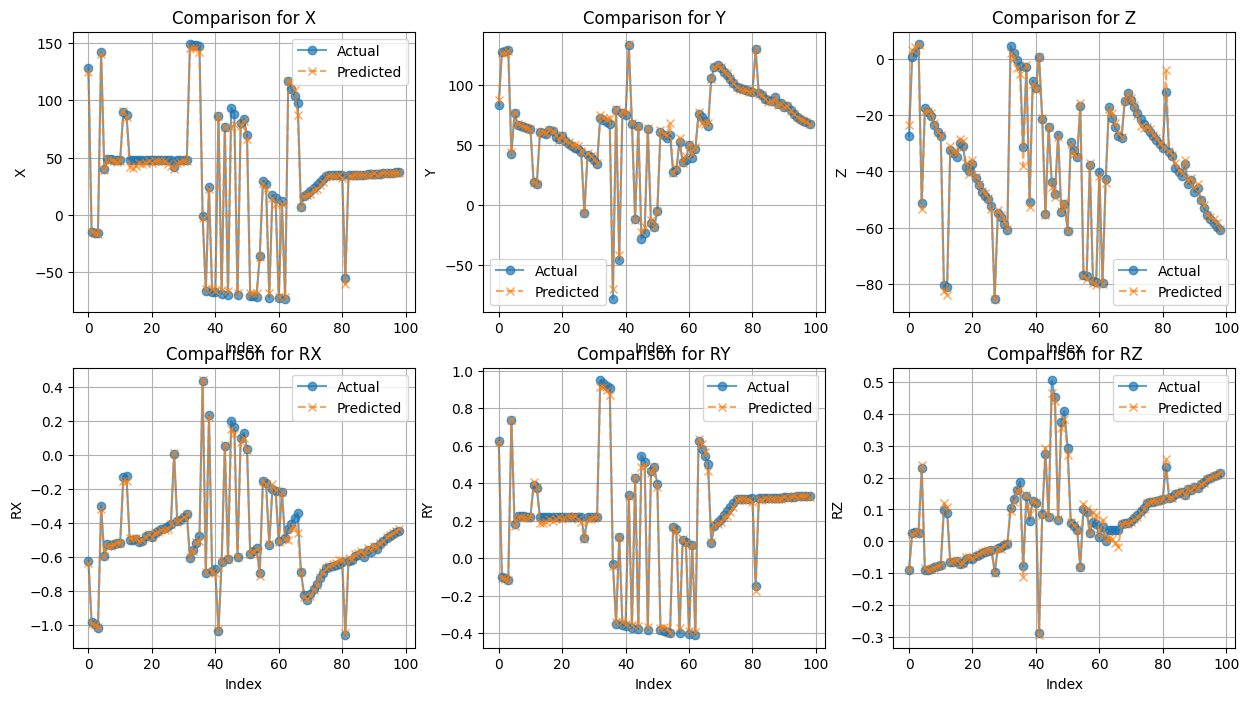

In [ ]:
#@title Importing results check in simulation
with open("tested_rfr.txt", 'r') as file:
    res = [[float(i) for i in x.strip().split(',')] for x in file.readlines()]


count = sum(1 for sublist in res if all(item == 999 for item in sublist))
print(f'There are {count} failed simulations, which is {(count/len(res))*100}%\n')

predicted = np.array(res)
actual = X

plot_comparison(X, res, labels=['X', 'Y', 'Z', 'RX', 'RY', 'RZ'])

##<font color='orange'>PolynomialFeatures model evaluation

Performance Metrics:
Target L1:
  Mean Squared Error: 0.4257
  R2 Score: 0.9995
Target L2:
  Mean Squared Error: 0.7828
  R2 Score: 0.9987
Target L3:
  Mean Squared Error: 0.5409
  R2 Score: 0.9993
Target L4:
  Mean Squared Error: 0.9983
  R2 Score: 0.9984
Target L5:
  Mean Squared Error: 0.7622
  R2 Score: 0.9990


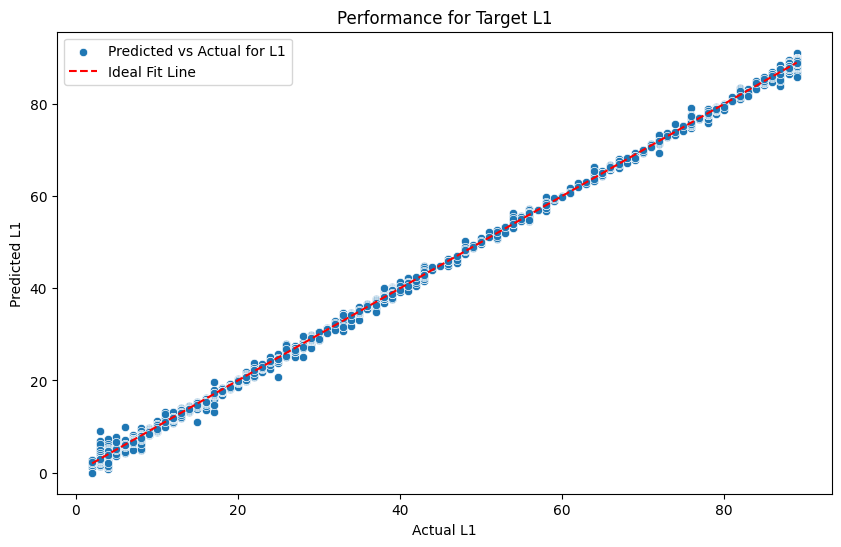

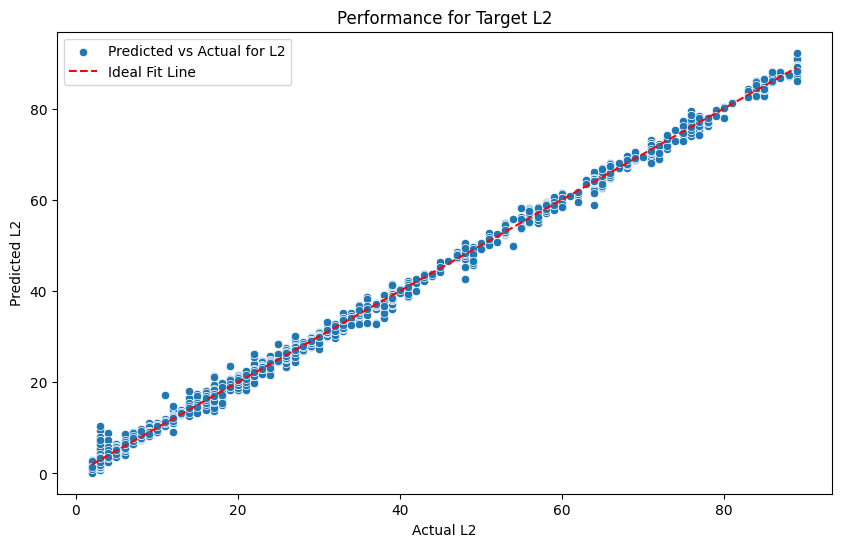

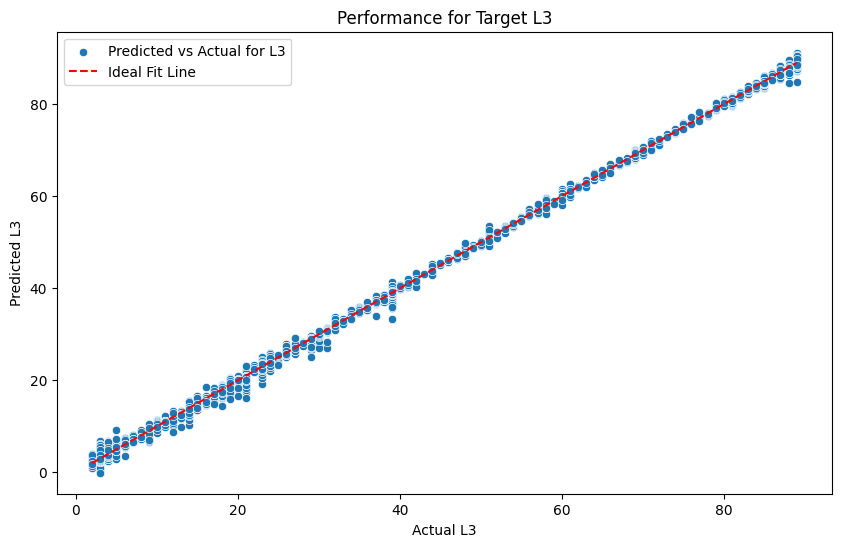

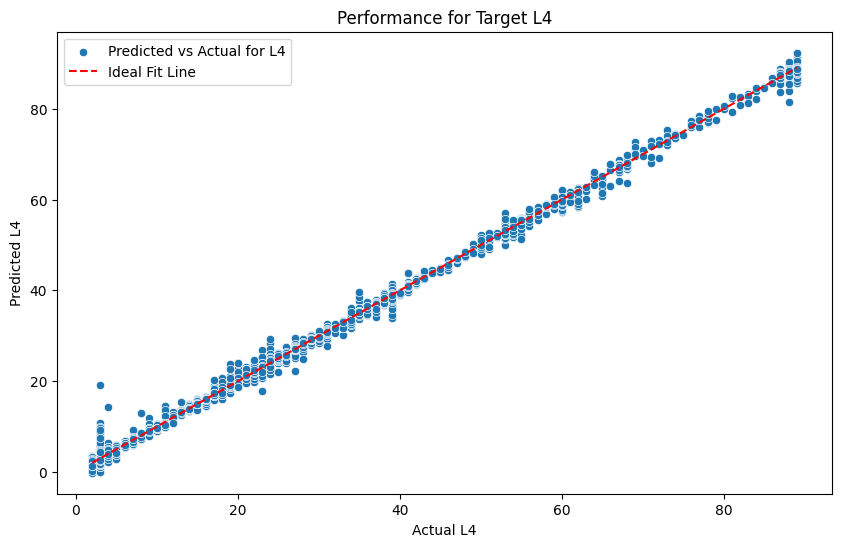

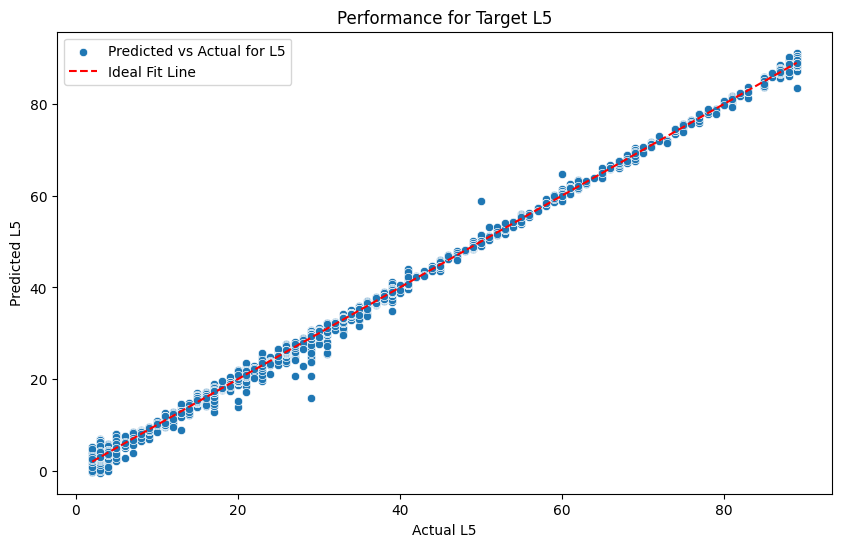

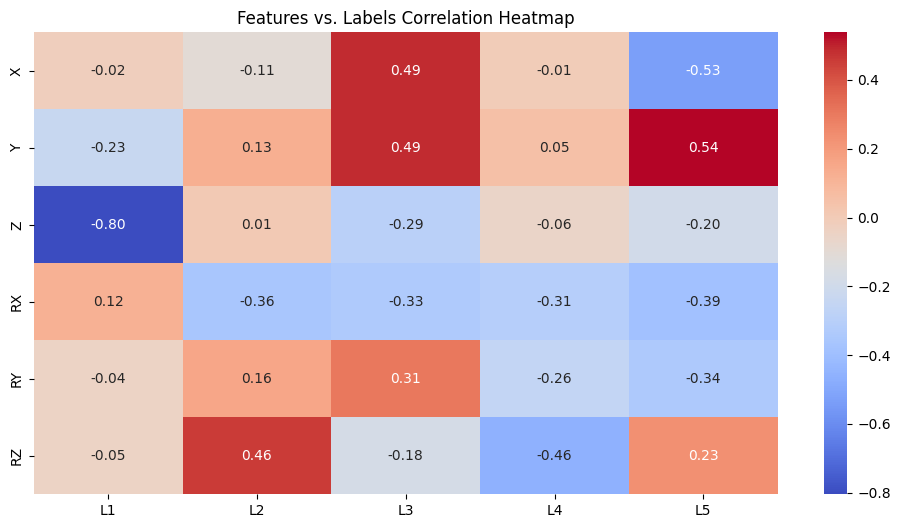

In [ ]:
#@title Defining and training the model
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline


labels = data[['L1', 'L2', 'L3', 'L4', 'L5']]
features = data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

degree = 5

model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred, multioutput='raw_values')
r2 = r2_score(y_test, y_pred, multioutput='raw_values')

print("Performance Metrics:")
for i, target in enumerate(labels.columns):
    print(f"Target {target}:")
    print(f"  Mean Squared Error: {mse[i]:.4f}")
    print(f"  R2 Score: {r2[i]:.4f}")

# Visualization
for i, target in enumerate(labels.columns):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_test.iloc[:, i], y=y_pred[:, i], label=f'Predicted vs Actual for {target}')
    plt.plot([y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             [y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             color='red', linestyle='--', label='Ideal Fit Line')
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Performance for Target {target}")
    plt.legend()
    plt.show()

plt.figure(figsize=(12, 6))

#sns.heatmap(pd.DataFrame(y_pred[:5], columns=labels.columns, index=[f"Sample {i+1}" for i in range(5)]), annot=True, fmt=".2f", cmap='coolwarm', cbar=True) # Heatmap through 5 samples

correlation_matrix = pd.concat([features, labels], axis=1).corr()
sns.heatmap(correlation_matrix.loc[features.columns, labels.columns], annot=True, cmap='coolwarm', fmt=".2f")

plt.title("Features vs. Labels Correlation Heatmap")
plt.show()

In [ ]:
#@title Validating using unseen data
new_data = pd.read_csv('filtered_second.csv').drop_duplicates()
#print(data)


X = new_data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']].values[:100]
y = new_data[['L1', 'L2', 'L3', 'L4', 'L5']].values[:100]

def make_prediction(desired):
    feature_names = ['X', 'Y', 'Z', 'RX', 'RY', 'RZ'] # there were too many warning because of passing np array without features names
    xyzrxryrz = pd.DataFrame([desired], columns=feature_names)

    prediction = model.predict(xyzrxryrz)

    res = prediction[0].tolist()

    return res

res = []
for i in X:
    y_pred = make_prediction(i)
    res.append(y_pred)

res = np.array(res)

#print(res)

# writing predicted configurations into a text file for further validation in simulation
with open('predictions_pf.txt', 'w') as writefile:
    for i in res:
        #print(i)
        writefile.write(f'{i[0]}, {i[1]}, {i[2]}, {i[3]}, {i[4]}\n')

There are 0 failed simulations, which is 0.0%

Accuracy for X: 98.95%
Accuracy for Y: 98.90%
Accuracy for Z: 90.72%
Accuracy for RX: 98.67%
Accuracy for RY: 99.09%
Accuracy for RZ: 95.27%


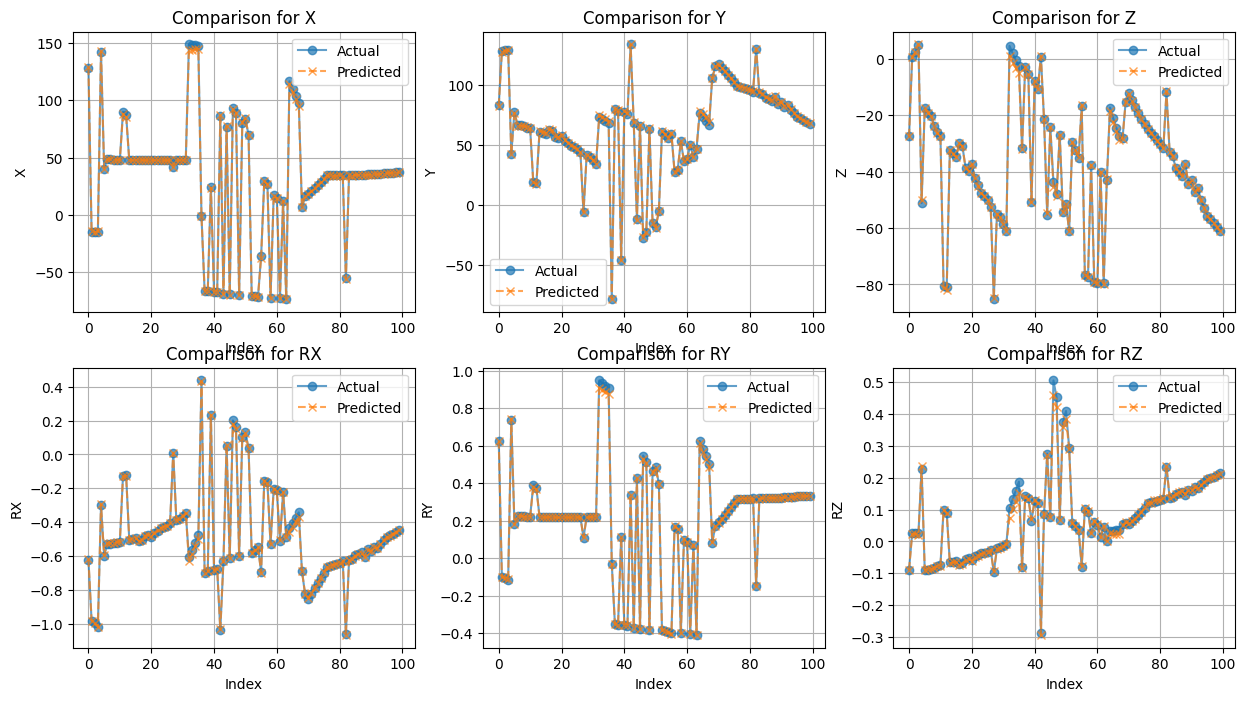

In [ ]:
#@title Importing results check in simulation
with open("tested_pf.txt", 'r') as file:
    res = [[float(i) for i in x.strip().split(',')] for x in file.readlines()]


count = sum(1 for sublist in res if all(item == 999 for item in sublist))
print(f'There are {count} failed simulations, which is {(count/len(res))*100}%\n')

predicted = np.array(res)
actual = X

plot_comparison(X, res, labels=['X', 'Y', 'Z', 'RX', 'RY', 'RZ'])

##<font color='red'> Conclusion:

Polynomial Features model performs quite well on this problem, having the lowest accuracy of 90.72% for linear Z component of the pose.

It is not quite possible to define all of the mechanical restrictions in the ML or NN model, meaning that both of those will depend on the dataset only.

It is also known that ML models are bad at extrapolation when NN perform there quite well, but because of mechanical restrictions cannot be tought to NN model, there is no much sense in using it.

All in all, I recommend Polynomial Features model for testings on the prototype!